# WineLens: Exploratory Data Analysis and Wine Quality Modeling

**Project type:** Data science / supervised machine learning  
**Dataset:** UCI Wine Quality dataset (red and white vinho verde samples)  
**Target:** Recorded wine quality score

## Project objectives
1. Understand the red and white wine datasets and assess data quality.
2. Explore how physicochemical measurements relate to recorded quality scores.
3. Build and compare regression models for red-wine quality prediction.
4. Investigate feature importance and prediction errors.
5. Compare regression with direct classification of integer quality categories.

> **Scope note:** Modeling experiments focus on the red-wine dataset. Exploratory analyses also compare red and white wine. These results describe this dataset and the evaluated split; they do not establish causal relationships or guarantee performance on wines from other sources.


In [1]:
# Imports and reproducibility settings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")


## 1. Load the datasets

The CSV files are semicolon-delimited and live in the `Datasets/` folder. Run the notebook from the project root (or update the paths below).

In [2]:
# Correctly parse the semicolon-delimited CSV files
df1 = pd.read_csv("Datasets/winequality-red.csv", sep=";")
df2 = pd.read_csv("Datasets/winequality-white.csv", sep=";")

print("Red wine shape:", df1.shape)
print("White wine shape:", df2.shape)
display(df1.head())
display(df2.head())


Red wine shape: (1599, 12)
White wine shape: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
df1.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [4]:
def inspect_dataset(df, name):
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nShape:", df.shape)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nExact duplicate rows:", df.duplicated().sum())

    print("\nDescriptive statistics:")
    display(df.describe().T)

inspect_dataset(df1, "Red Wine")
inspect_dataset(df2, "White Wine")


Red Wine

Shape: (1599, 12)

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Exact duplicate rows: 240

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000



White Wine

Shape: (4898, 12)

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Exact duplicate rows: 937

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.854788,0.843868,3.80000,6.300000,6.80000,7.3000,14.20000
volatile acidity,4898.0,0.278241,0.100795,0.08000,0.210000,0.26000,0.3200,1.10000
citric acid,4898.0,0.334192,0.121020,0.00000,0.270000,0.32000,0.3900,1.66000
residual sugar,4898.0,6.391415,5.072058,0.60000,1.700000,5.20000,9.9000,65.80000
chlorides,4898.0,0.045772,0.021848,0.00900,0.036000,0.04300,0.0500,0.34600
free sulfur dioxide,4898.0,35.308085,17.007137,2.00000,23.000000,34.00000,46.0000,289.00000
total sulfur dioxide,4898.0,138.360657,42.498065,9.00000,108.000000,134.00000,167.0000,440.00000
density,4898.0,0.994027,0.002991,0.98711,0.991723,0.99374,0.9961,1.03898
pH,4898.0,3.188267,0.151001,2.72000,3.090000,3.18000,3.2800,3.82000
sulphates,4898.0,0.489847,0.114126,0.22000,0.410000,0.47000,0.5500,1.08000


## 2. Combined exploratory dataset

The combined dataframe is used for comparisons by wine type. The `wine_type` column is an EDA label; it is not used as a predictor in the red-wine models below.

In [5]:
df_red_eda = df1.copy()
df_white_eda = df2.copy()

df_red_eda["wine_type"] = "Red"
df_white_eda["wine_type"] = "White"

df = pd.concat(
    [df_red_eda, df_white_eda],
    ignore_index=True
)

print("Combined shape:", df.shape)
print("\nWine type counts:")
print(df["wine_type"].value_counts())

display(df.head())

Combined shape: (6497, 13)

Wine type counts:
wine_type
White    4898
Red      1599
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red


## 3. Target distributions and exploratory analysis

The target is an integer quality rating. Its distribution is imbalanced, so overall accuracy alone may not tell the full story for classification.

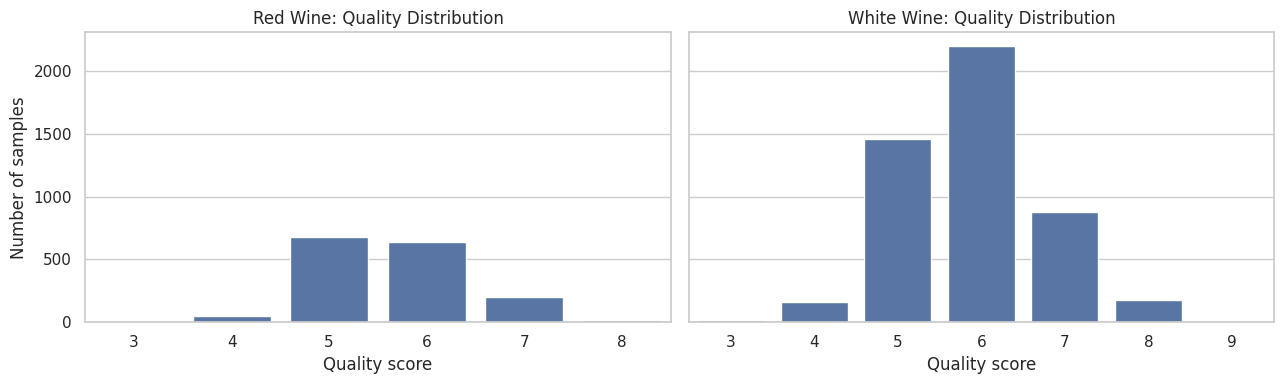

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

sns.countplot(data=df1, x="quality", ax=axes[0])
axes[0].set_title("Red Wine: Quality Distribution")
axes[0].set_xlabel("Quality score")
axes[0].set_ylabel("Number of samples")

sns.countplot(data=df2, x="quality", ax=axes[1])
axes[1].set_title("White Wine: Quality Distribution")
axes[1].set_xlabel("Quality score")
axes[1].set_ylabel("Number of samples")

plt.tight_layout()
plt.show()

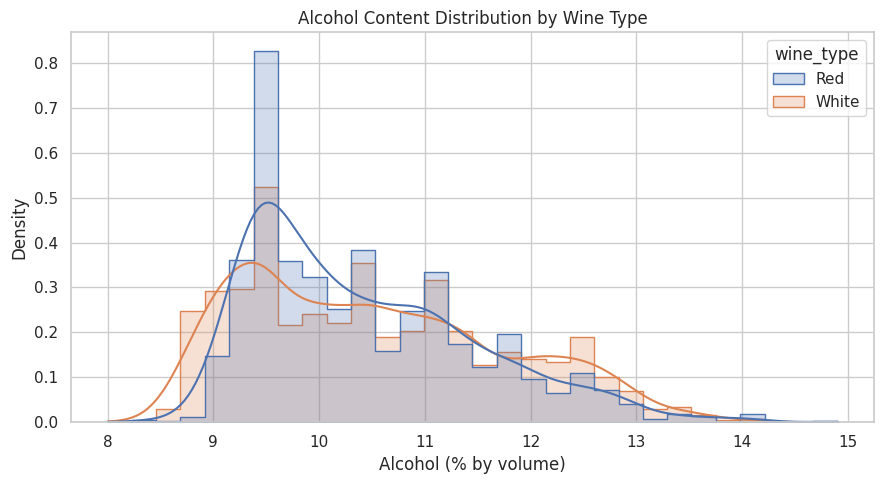

In [7]:
# Re-created the combined DataFrame correctly with the properly split datasets
df_red_eda = df1.copy()
df_white_eda = df2.copy()

df_red_eda["wine_type"] = "Red"
df_white_eda["wine_type"] = "White"

df = pd.concat([df_red_eda, df_white_eda], ignore_index=True)

# Alcohol distribution by wine type
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="alcohol",
    hue="wine_type",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Alcohol Content Distribution by Wine Type")
plt.xlabel("Alcohol (% by volume)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

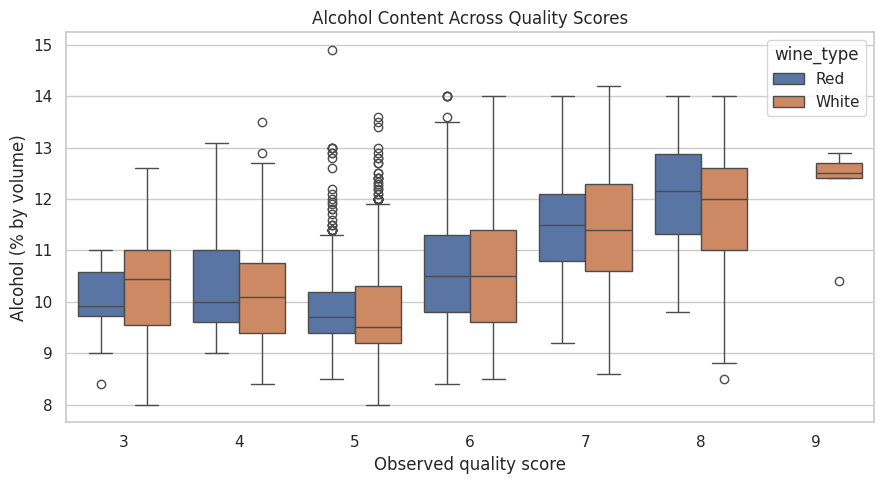

In [8]:
#Alcohol versus quality


plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="quality",
    y="alcohol",
    hue="wine_type"
)

plt.title("Alcohol Content Across Quality Scores")
plt.xlabel("Observed quality score")
plt.ylabel("Alcohol (% by volume)")
plt.tight_layout()
plt.show()

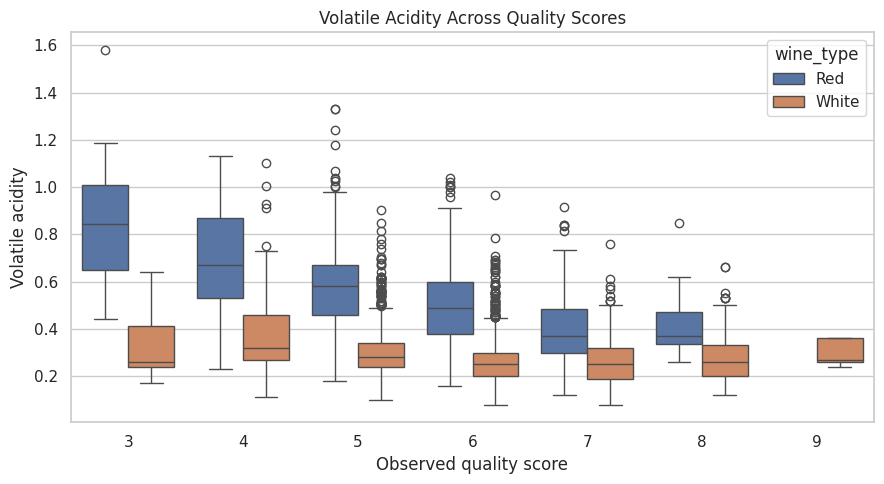

In [9]:
#Volatile acidity versus quality

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="quality",
    y="volatile acidity",
    hue="wine_type"
)

plt.title("Volatile Acidity Across Quality Scores")
plt.xlabel("Observed quality score")
plt.ylabel("Volatile acidity")
plt.tight_layout()
plt.show()

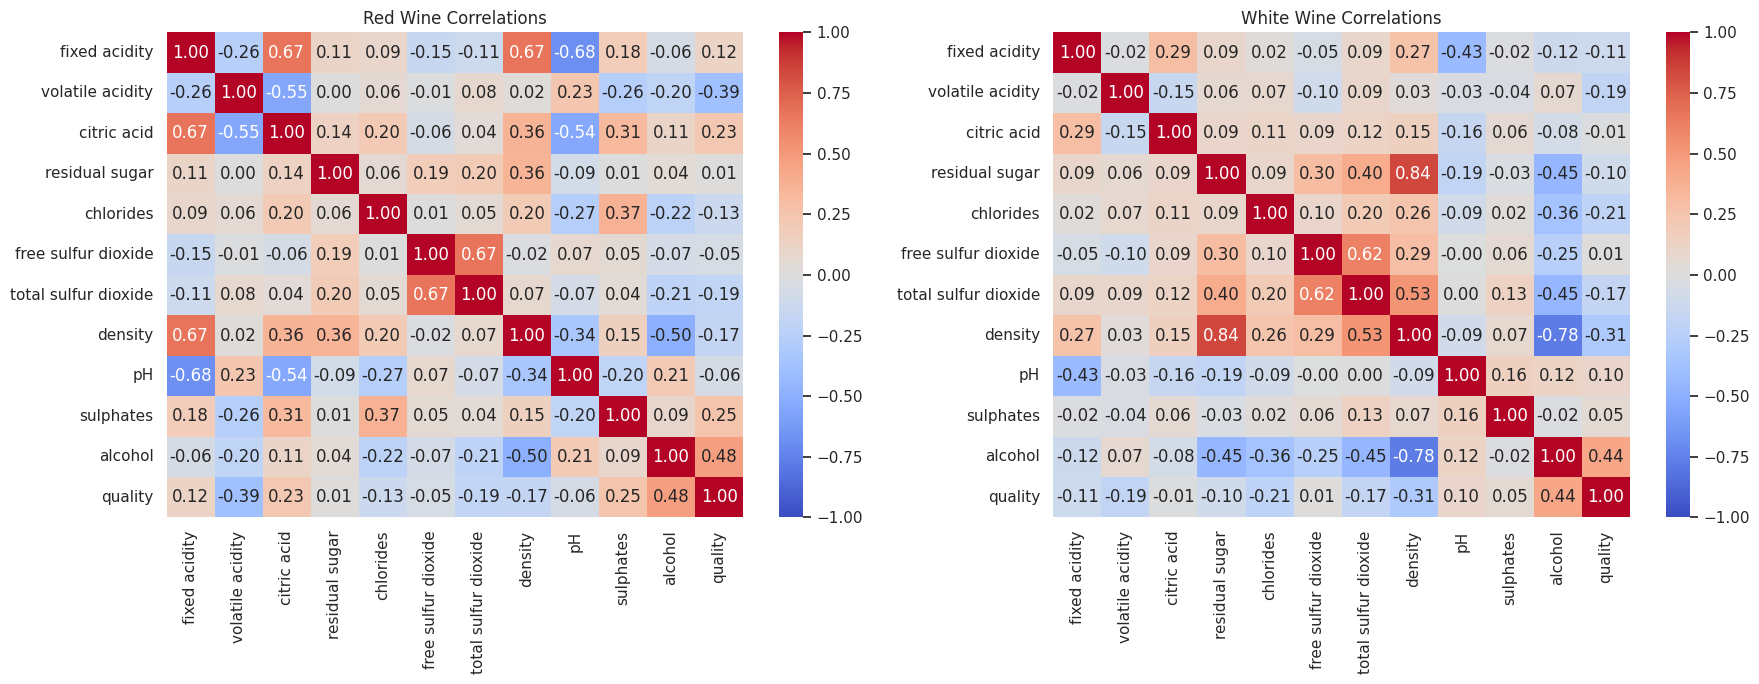

In [10]:
#Correlation heatmap

numeric_cols = df1.columns

corr_red = df1[numeric_cols].corr()
corr_white = df2[numeric_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    corr_red,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    ax=axes[0]
)
axes[0].set_title("Red Wine Correlations")

sns.heatmap(
    corr_white,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    ax=axes[1]
)
axes[1].set_title("White Wine Correlations")

plt.tight_layout()
plt.show()

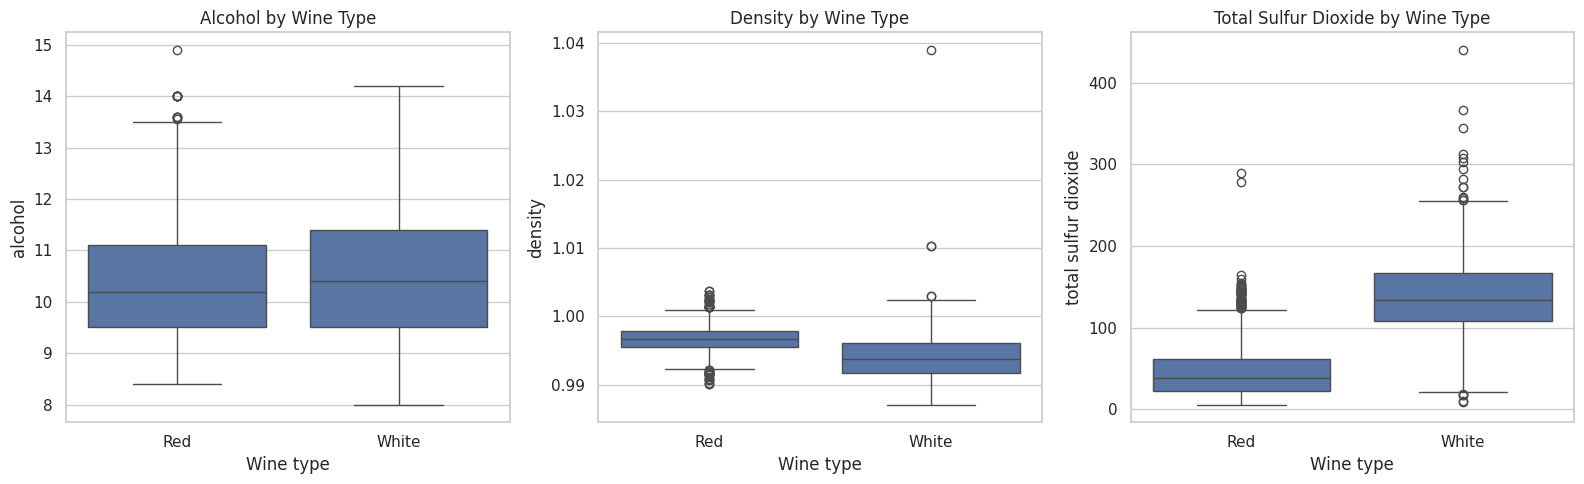

In [11]:
#Compare key measurements between red and white wine

features = [
    "alcohol",
    "density",
    "total sulfur dioxide"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x="wine_type",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature.title()} by Wine Type")
    ax.set_xlabel("Wine type")

plt.tight_layout()
plt.show()

In [12]:
#Extract numerical findings for your report

# Quality distribution
print("RED WINE — quality counts")
display(df1["quality"].value_counts().sort_index())

print("WHITE WINE — quality counts")
display(df2["quality"].value_counts().sort_index())

# Comparing summary statistics by wine type
summary = df.groupby("wine_type")[
    ["quality", "alcohol", "volatile acidity",
     "density", "residual sugar", "chlorides"]
].agg(["mean", "median", "std"])

display(summary.round(3))

# Correlation of features with quality
for name, data in [
    ("Red", df1),
    ("White", df2)
]:
    print(f"\n{name}: feature correlations with quality")

    correlations = (
        data.corr(numeric_only=True)["quality"]
        .drop("quality")
        .sort_values(key=abs, ascending=False)
    )

    display(correlations.to_frame("Pearson correlation").round(3))

RED WINE — quality counts


,count
quality,
3,10
4,53
5,681
6,638
7,199
8,18


WHITE WINE — quality counts


,count
quality,
3,20
4,163
5,1457
6,2198
7,880
8,175
9,5


quality               alcohol               volatile acidity         \
             mean median    std    mean median    std             mean median   
wine_type                                                                       
Red         5.636    6.0  0.808  10.423   10.2  1.066            0.528   0.52   
White       5.878    6.0  0.886  10.514   10.4  1.231            0.278   0.26   

                 density               residual sugar               chlorides  \
             std    mean median    std           mean median    std      mean   
wine_type                                                                       
Red        0.179   0.997  0.997  0.002          2.539    2.2  1.410     0.087   
White      0.101   0.994  0.994  0.003          6.391    5.2  5.072     0.046   

                         
          median    std  
wine_type                
Red        0.079  0.047  
White      0.043  0.022


Red: feature correlations with quality


,Pearson correlation
alcohol,0.476
volatile acidity,-0.391
sulphates,0.251
citric acid,0.226
total sulfur dioxide,-0.185
density,-0.175
chlorides,-0.129
fixed acidity,0.124
pH,-0.058
free sulfur dioxide,-0.051



White: feature correlations with quality


,Pearson correlation
alcohol,0.436
density,-0.307
chlorides,-0.210
volatile acidity,-0.195
total sulfur dioxide,-0.175
fixed acidity,-0.114
pH,0.099
residual sugar,-0.098
sulphates,0.054
citric acid,-0.009


In [13]:
import pandas as pd

datasets = {
    "Red wine (df1)": df1,
    "White wine (df2)": df2
}

for name, data in datasets.items():
    print(f"\n{'=' * 45}")
    print(name)
    print("Shape:", data.shape)
    print("Missing cells:", data.isna().sum().sum())
    print("Duplicate rows:", data.duplicated().sum())
    print("Duplicate percentage:",
          round(data.duplicated().mean() * 100, 2), "%")


Red wine (df1)
Shape: (1599, 12)
Missing cells: 0
Duplicate rows: 240
Duplicate percentage: 15.01 %

White wine (df2)
Shape: (4898, 12)
Missing cells: 0
Duplicate rows: 937
Duplicate percentage: 19.13 %


In [14]:
datasets = {
    "Red wine": df1,
    "White wine": df2
}

for name, data in datasets.items():
    cleaned = data.drop_duplicates()

    print(f"\n--- {name} ---")
    print("Original rows:", len(data))
    print("Rows after deduplication:", len(cleaned))
    print("Rows removed:", len(data) - len(cleaned))

    comparison = pd.DataFrame({
        "Before (%)": data["quality"].value_counts(normalize=True).sort_index() * 100,
        "After (%)": cleaned["quality"].value_counts(normalize=True).sort_index() * 100
    }).round(2)

    print("\nQuality distribution:")
    print(comparison)


--- Red wine ---
Original rows: 1599
Rows after deduplication: 1359
Rows removed: 240

Quality distribution:
         Before (%)  After (%)
quality                       
3              0.63       0.74
4              3.31       3.90
5             42.59      42.46
6             39.90      39.37
7             12.45      12.29
8              1.13       1.25

--- White wine ---
Original rows: 4898
Rows after deduplication: 3961
Rows removed: 937

Quality distribution:
         Before (%)  After (%)
quality                       
3              0.41       0.50
4              3.33       3.86
5             29.75      29.66
6             44.88      45.14
7             17.97      17.39
8              3.57       3.31
9              0.10       0.13


In [15]:
# Preserved original datasets
red_original = df1.copy()
white_original = df2.copy()

# Created deduplicated alternatives
red_dedup = red_original.drop_duplicates()
white_dedup = white_original.drop_duplicates()

print("Red original:", red_original.shape)
print("Red deduplicated:", red_dedup.shape)

print("White original:", white_original.shape)
print("White deduplicated:", white_dedup.shape)

Red original: (1599, 12)
Red deduplicated: (1359, 12)
White original: (4898, 12)
White deduplicated: (3961, 12)


**Feature Engineering**

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

red = df1.copy()
white = df2.copy()

# Confirmedf the CSV was parsed correctly
for name, data in [("Red", red), ("White", white)]:
    print(f"\n--- {name} wine ---")
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Non-numeric columns:", data.select_dtypes(exclude="number").columns.tolist())
    print("Missing cells:", data.isna().sum().sum())


--- Red wine ---
Shape: (1599, 12)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Non-numeric columns: []
Missing cells: 0

--- White wine ---
Shape: (4898, 12)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Non-numeric columns: []
Missing cells: 0



--- Red wine: feature correlation with quality ---
volatile acidity       -0.391
total sulfur dioxide   -0.185
density                -0.175
chlorides              -0.129
pH                     -0.058
free sulfur dioxide    -0.051
residual sugar          0.014
fixed acidity           0.124
citric acid             0.226
sulphates               0.251
alcohol                 0.476
Name: quality, dtype: float64


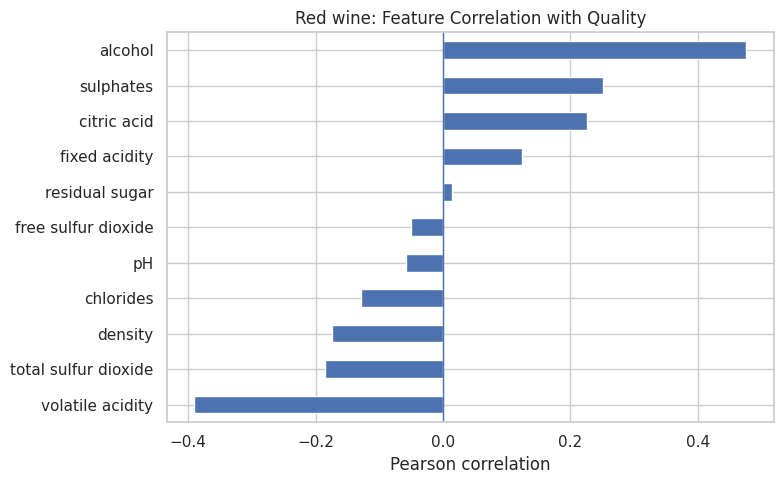


--- White wine: feature correlation with quality ---
density                -0.307
chlorides              -0.210
volatile acidity       -0.195
total sulfur dioxide   -0.175
fixed acidity          -0.114
residual sugar         -0.098
citric acid            -0.009
free sulfur dioxide     0.008
sulphates               0.054
pH                      0.099
alcohol                 0.436
Name: quality, dtype: float64


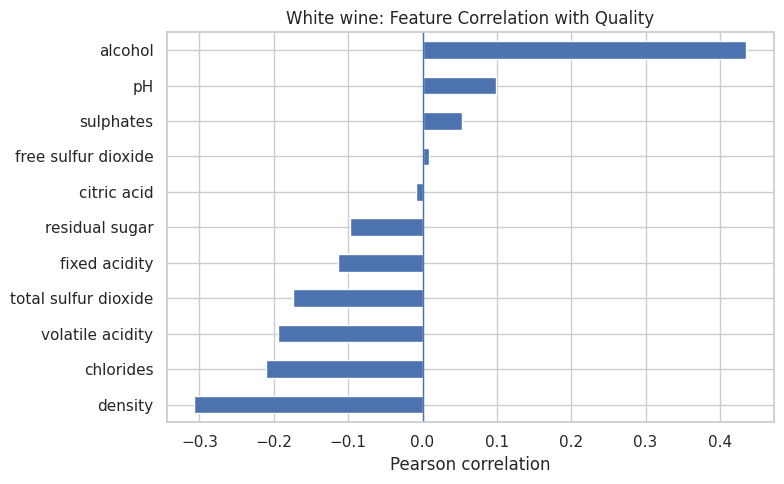

In [17]:
for name, data in [("Red wine", red), ("White wine", white)]:
    correlations = (
        data.corr(numeric_only=True)["quality"]
        .drop("quality")
        .sort_values()
    )

    print(f"\n--- {name}: feature correlation with quality ---")
    print(correlations.round(3))

    plt.figure(figsize=(8, 5))
    correlations.plot(kind="barh")
    plt.axvline(0, linewidth=1)
    plt.title(f"{name}: Feature Correlation with Quality")
    plt.xlabel("Pearson correlation")
    plt.tight_layout()
    plt.show()

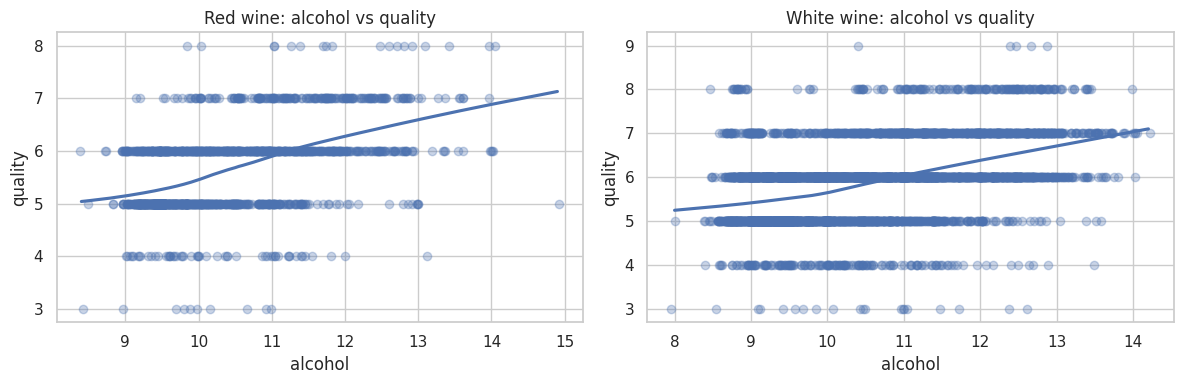

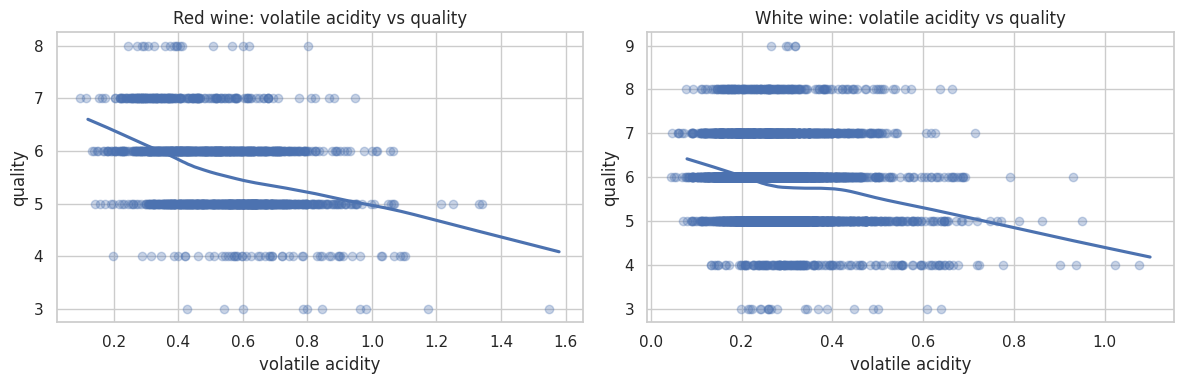

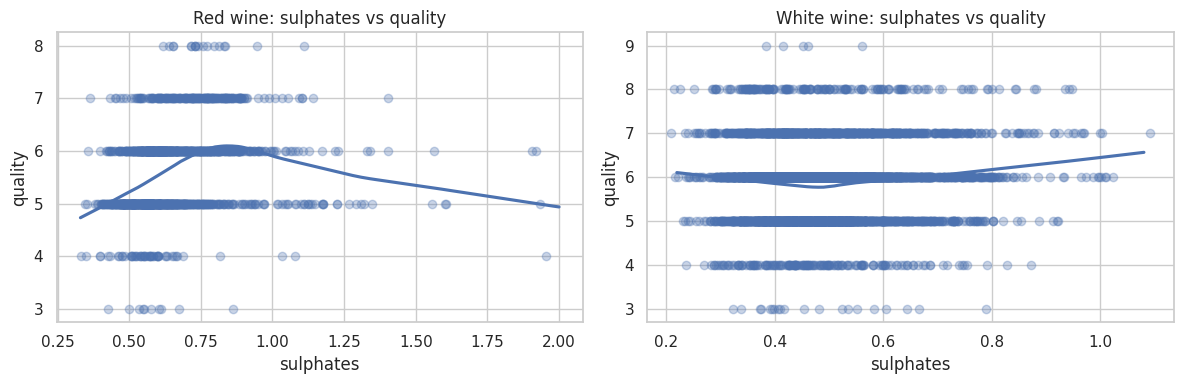

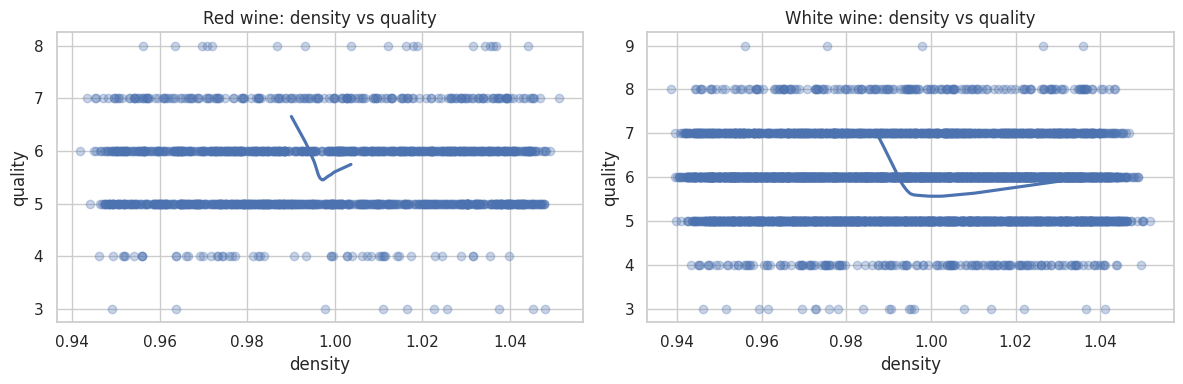

In [18]:
features_to_check = [
    "alcohol",
    "volatile acidity",
    "sulphates",
    "density"
]

for feature in features_to_check:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.regplot(
        data=red, x=feature, y="quality",
        x_jitter=0.05, scatter_kws={"alpha": 0.3},
        ax=axes[0], lowess=True
    )
    axes[0].set_title(f"Red wine: {feature} vs quality")

    sns.regplot(
        data=white, x=feature, y="quality",
        x_jitter=0.05, scatter_kws={"alpha": 0.3},
        ax=axes[1], lowess=True
    )
    axes[1].set_title(f"White wine: {feature} vs quality")

    plt.tight_layout()
    plt.show()

In [19]:
numeric_features = [
    col for col in red.select_dtypes(include="number").columns
    if col != "quality"
]

def iqr_outlier_report(data, name):
    rows = []

    for feature in numeric_features:
        q1 = data[feature].quantile(0.25)
        q3 = data[feature].quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        count = ((data[feature] < lower) | (data[feature] > upper)).sum()

        rows.append({
            "feature": feature,
            "lower_bound": round(lower, 3),
            "upper_bound": round(upper, 3),
            "outlier_count": int(count),
            "outlier_percentage": round(count / len(data) * 100, 2)
        })

    result = pd.DataFrame(rows).sort_values(
        "outlier_percentage", ascending=False
    )

    print(f"\n--- {name} ---")
    display(result)

for name, data in [("Red wine", red), ("White wine", white)]:
    iqr_outlier_report(data, name)


--- Red wine ---


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
3,residual sugar,0.850,3.650,155,9.69
4,chlorides,0.040,0.120,112,7.00
9,sulphates,0.280,1.000,59,3.69
6,total sulfur dioxide,-38.000,122.000,55,3.44
0,fixed acidity,3.950,12.350,49,3.06
7,density,0.992,1.001,45,2.81
8,pH,2.925,3.685,35,2.19
5,free sulfur dioxide,-14.000,42.000,30,1.88
1,volatile acidity,0.015,1.015,19,1.19
10,alcohol,7.100,13.500,13,0.81



--- White wine ---


,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
2,citric acid,0.090,0.570,270,5.51
4,chlorides,0.015,0.071,208,4.25
1,volatile acidity,0.045,0.485,186,3.80
9,sulphates,0.200,0.760,124,2.53
0,fixed acidity,4.800,8.800,119,2.43
8,pH,2.805,3.565,75,1.53
5,free sulfur dioxide,-11.500,80.500,50,1.02
6,total sulfur dioxide,19.500,255.500,19,0.39
3,residual sugar,-10.600,22.200,7,0.14
7,density,0.985,1.003,5,0.10


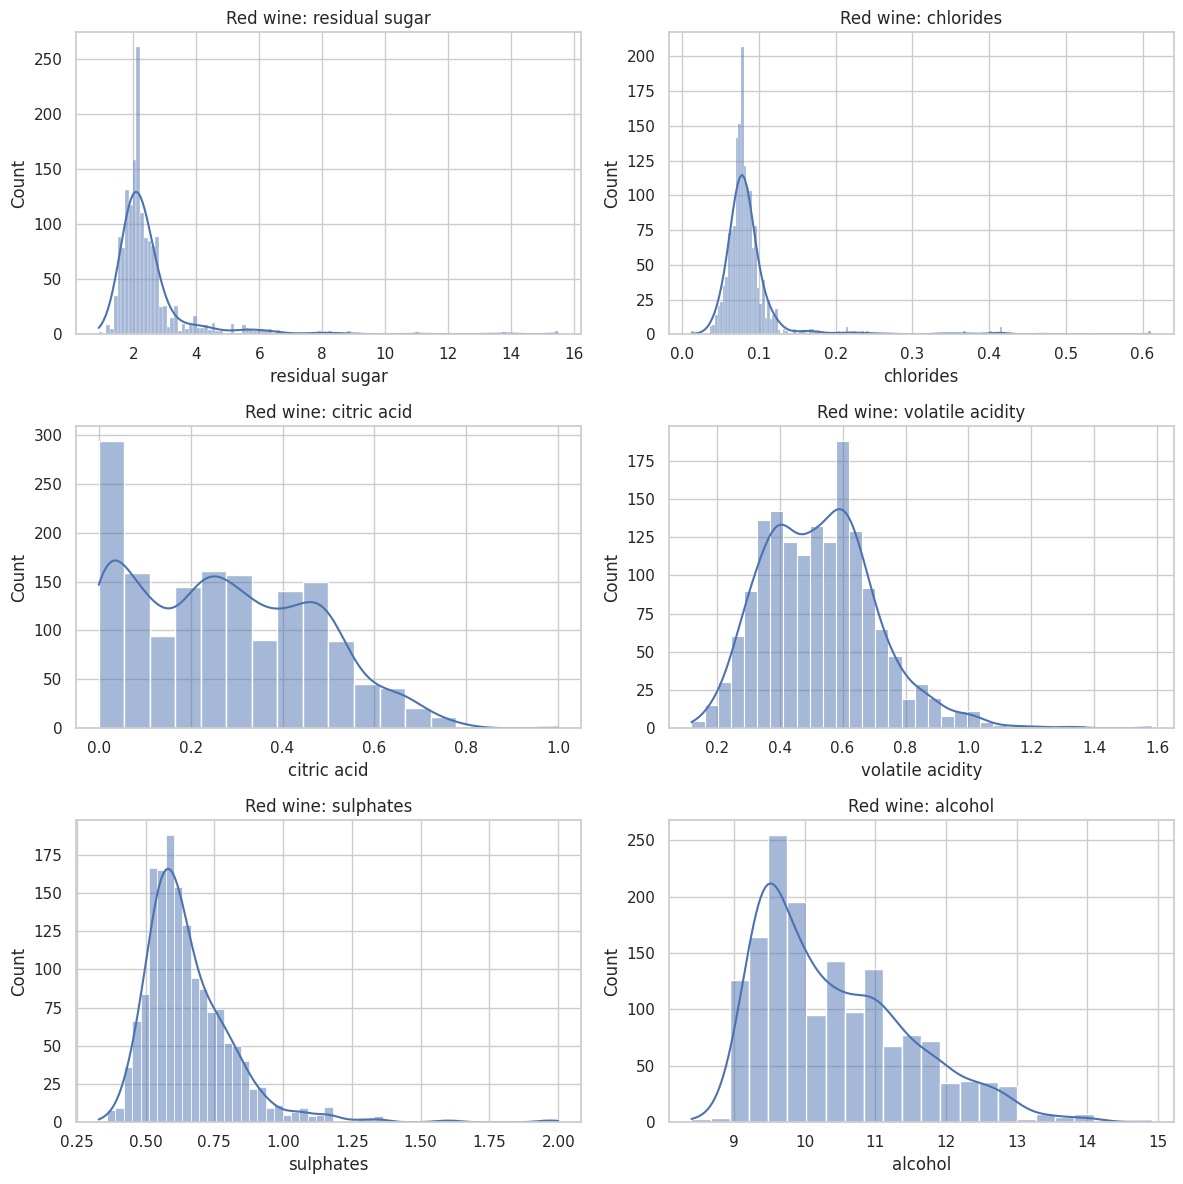

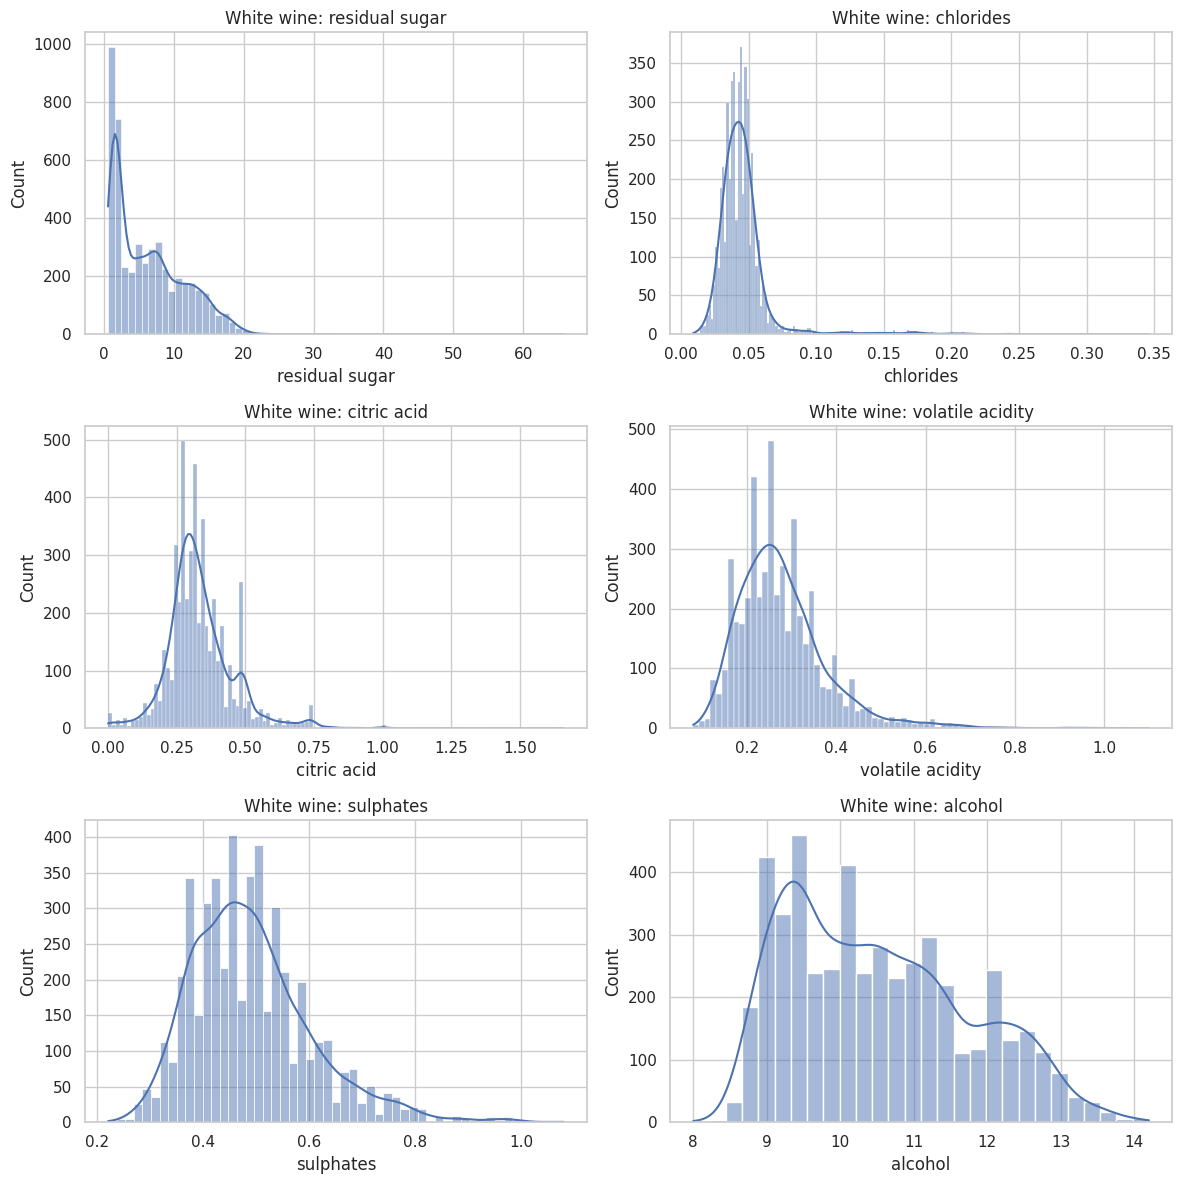

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "residual sugar",
    "chlorides",
    "citric acid",
    "volatile acidity",
    "sulphates",
    "alcohol"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, feature in zip(axes.flat, features):
    sns.histplot(
        data=df1,
        x=feature,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Red wine: {feature}")

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, feature in zip(axes.flat, features):
    sns.histplot(
        data=df2,
        x=feature,
        kde=True,
        ax=ax
    )
    ax.set_title(f"White wine: {feature}")

plt.tight_layout()
plt.show()


In [21]:

features = [
    "residual sugar",
    "chlorides",
    "citric acid",
    "volatile acidity",
    "sulphates",
    "alcohol"
]

for name, data in [("Red wine", df1), ("White wine", df2)]:
    print(f"\n--- {name} ---")

    result = pd.DataFrame({
        "Skewness": data[features].skew(),
        "Median": data[features].median(),
        "Mean": data[features].mean()
    }).round(3)

    display(result.sort_values("Skewness", ascending=False))



--- Red wine ---


,Skewness,Median,Mean
chlorides,5.680,0.079,0.087
residual sugar,4.541,2.200,2.539
sulphates,2.429,0.620,0.658
alcohol,0.861,10.200,10.423
volatile acidity,0.672,0.520,0.528
citric acid,0.318,0.260,0.271



--- White wine ---


,Skewness,Median,Mean
chlorides,5.023,0.043,0.046
volatile acidity,1.577,0.260,0.278
citric acid,1.282,0.320,0.334
residual sugar,1.077,5.200,6.391
sulphates,0.977,0.470,0.490
alcohol,0.487,10.400,10.514


In [22]:

import numpy as np
import pandas as pd

features_to_test = [
    "chlorides",
    "residual sugar",
    "sulphates",
    "volatile acidity",
    "citric acid"
]

for name, data in [("Red wine", df1), ("White wine", df2)]:
    rows = []

    for feature in features_to_test:
        original = data[feature]
        transformed = np.log1p(original)

        rows.append({
            "Feature": feature,
            "Original skewness": original.skew(),
            "Log1p skewness": transformed.skew(),
            "Absolute skew reduced": (
                abs(original.skew()) - abs(transformed.skew())
            ).round(3)
        })

    print(f"\n--- {name} ---")
    display(pd.DataFrame(rows).round(3))



--- Red wine ---


,Feature,Original skewness,Log1p skewness,Absolute skew reduced
0,chlorides,5.680,5.071,0.609
1,residual sugar,4.541,2.255,2.286
2,sulphates,2.429,1.610,0.818
3,volatile acidity,0.672,0.270,0.401
4,citric acid,0.318,0.088,0.231



--- White wine ---


,Feature,Original skewness,Log1p skewness,Absolute skew reduced
0,chlorides,5.023,4.627,0.397
1,residual sugar,1.077,0.004,1.073
2,sulphates,0.977,0.706,0.271
3,volatile acidity,1.577,1.145,0.432
4,citric acid,1.282,0.612,0.670


In [23]:

for name, data in [("Red wine", df1), ("White wine", df2)]:
    print(f"\n{'=' * 55}")
    print(name)

    summary = pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "unique_values": data.nunique(),
        "minimum": data.min(numeric_only=True),
        "median": data.median(numeric_only=True),
        "maximum": data.max(numeric_only=True)
    })

    display(summary.round(3))

    # Check for impossible negative values in features
    nonnegative_features = [
        "residual sugar",
        "chlorides",
        "free sulfur dioxide",
        "total sulfur dioxide",
        "density",
        "alcohol"
    ]

    print("Negative-value checks:")
    for feature in nonnegative_features:
        print(
            f"{feature}:",
            int((data[feature] < 0).sum())
        )

    print("\nQuality score counts:")
    print(data["quality"].value_counts().sort_index())



Red wine


,dtype,unique_values,minimum,median,maximum
fixed acidity,float64,96,4.600,7.900,15.900
volatile acidity,float64,143,0.120,0.520,1.580
citric acid,float64,80,0.000,0.260,1.000
residual sugar,float64,91,0.900,2.200,15.500
chlorides,float64,153,0.012,0.079,0.611
free sulfur dioxide,float64,60,1.000,14.000,72.000
total sulfur dioxide,float64,144,6.000,38.000,289.000
density,float64,436,0.990,0.997,1.004
pH,float64,89,2.740,3.310,4.010
sulphates,float64,96,0.330,0.620,2.000


Negative-value checks:
residual sugar: 0
chlorides: 0
free sulfur dioxide: 0
total sulfur dioxide: 0
density: 0
alcohol: 0

Quality score counts:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

White wine


,dtype,unique_values,minimum,median,maximum
fixed acidity,float64,68,3.800,6.800,14.200
volatile acidity,float64,125,0.080,0.260,1.100
citric acid,float64,87,0.000,0.320,1.660
residual sugar,float64,310,0.600,5.200,65.800
chlorides,float64,160,0.009,0.043,0.346
free sulfur dioxide,float64,132,2.000,34.000,289.000
total sulfur dioxide,float64,251,9.000,134.000,440.000
density,float64,890,0.987,0.994,1.039
pH,float64,103,2.720,3.180,3.820
sulphates,float64,79,0.220,0.470,1.080


Negative-value checks:
residual sugar: 0
chlorides: 0
free sulfur dioxide: 0
total sulfur dioxide: 0
density: 0
alcohol: 0

Quality score counts:
quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


## 4. Modeling approach

The supervised modeling section uses red wine only. We keep a reproducible 80/20 train/test split (`random_state=42`) and use the training split for cross-validation during hyperparameter search.

**Evaluation caveat:** during the original exploratory workflow, the test set was consulted repeatedly for model comparisons, feature importance, transformation experiments, and classification. Therefore, these test metrics are useful exploratory results, but should not be presented as an untouched final estimate of generalization. A stronger final evaluation should reserve a new holdout or establish a fresh evaluation protocol before further model selection.


In [24]:

from sklearn.model_selection import train_test_split

# Copying the original red wine dataset
red_ml = df1.copy()

# Separated predictors and target
X_red = red_ml.drop(columns=["quality"])
y_red = red_ml["quality"]

# Reproducible 80/20 split
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_red,
    y_red,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train_red.shape)
print("Testing features:", X_test_red.shape)
print("Training targets:", y_train_red.shape)
print("Testing targets:", y_test_red.shape)

print("\nTraining quality distribution:")
print(y_train_red.value_counts().sort_index())

print("\nTesting quality distribution:")
print(y_test_red.value_counts().sort_index())


Training features: (1279, 11)
Testing features: (320, 11)
Training targets: (1279,)
Testing targets: (320,)

Training quality distribution:
quality
3      9
4     43
5    551
6    506
7    157
8     13
Name: count, dtype: int64

Testing quality distribution:
quality
3      1
4     10
5    130
6    132
7     42
8      5
Name: count, dtype: int64


In [25]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Baseline: predict the mean quality from training data
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train_red, y_train_red)

# Evaluated on the held-out test set
y_pred_dummy = dummy.predict(X_test_red)

dummy_results = {
    "Model": "Dummy Regressor (mean)",
    "MAE": mean_absolute_error(y_test_red, y_pred_dummy),
    "RMSE": np.sqrt(mean_squared_error(y_test_red, y_pred_dummy)),
    "R²": r2_score(y_test_red, y_pred_dummy)
}

display(pd.DataFrame([dummy_results]).round(4))

print("Constant prediction:", round(float(dummy.constant_[0]), 4))


,Model,MAE,RMSE,R²
0,Dummy Regressor (mean),0.6853,0.8107,-0.0056


Constant prediction: 5.6239


/tmp/ipykernel_1213/4130738155.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Constant prediction:", round(float(dummy.constant_[0]), 4))


In [26]:
#Training with Linear Regression


from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Trained on training data only
linear_model = LinearRegression()
linear_model.fit(X_train_red, y_train_red)

# Predicted the held-out test data
y_pred_linear = linear_model.predict(X_test_red)

linear_results = {
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test_red, y_pred_linear),
    "RMSE": np.sqrt(mean_squared_error(y_test_red, y_pred_linear)),
    "R²": r2_score(y_test_red, y_pred_linear)
}

comparison = pd.DataFrame([
    dummy_results,
    linear_results
])

display(comparison.round(4))


,Model,MAE,RMSE,R²
0,Dummy Regressor (mean),0.6853,0.8107,-0.0056
1,Linear Regression,0.5035,0.6245,0.4032


In [27]:
#Ridge Regression


from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Standardization is fitted on training data only
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train_red, y_train_red)

y_pred_ridge = ridge_model.predict(X_test_red)

ridge_results = {
    "Model": "Ridge Regression (alpha=1.0)",
    "MAE": mean_absolute_error(y_test_red, y_pred_ridge),
    "RMSE": np.sqrt(mean_squared_error(y_test_red, y_pred_ridge)),
    "R²": r2_score(y_test_red, y_pred_ridge)
}

comparison = pd.DataFrame([
    dummy_results,
    linear_results,
    ridge_results
])

display(comparison.round(4))


,Model,MAE,RMSE,R²
0,Dummy Regressor (mean),0.6853,0.8107,-0.0056
1,Linear Regression,0.5035,0.6245,0.4032
2,Ridge Regression (alpha=1.0),0.5036,0.6245,0.4032


In [28]:
#Tune Ridge with cross-validation


from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
import pandas as pd

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

param_grid = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train_red, y_train_red)

cv_results = pd.DataFrame(ridge_search.cv_results_)[[
    "param_ridge__alpha",
    "mean_test_score",
    "std_test_score"
]].copy()

cv_results["mean_CV_MAE"] = -cv_results["mean_test_score"]
cv_results = cv_results.drop(columns="mean_test_score")

print("Best alpha:", ridge_search.best_params_["ridge__alpha"])
print("Best mean CV MAE:", round(-ridge_search.best_score_, 4))

display(
    cv_results.rename(columns={
        "param_ridge__alpha": "alpha",
        "std_test_score": "CV MAE std"
    }).drop_duplicates().round(4)
)


Best alpha: 10
Best mean CV MAE: 0.5056


,alpha,CV MAE std,mean_CV_MAE
0,0.01,0.0178,0.5057
1,0.10,0.0178,0.5057
2,1.00,0.0178,0.5057
3,10.00,0.0178,0.5056
4,100.00,0.0177,0.5071


In [29]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Best estimator was refitted on the full training set by GridSearchCV
best_ridge = ridge_search.best_estimator_

y_pred_ridge_tuned = best_ridge.predict(X_test_red)

tuned_ridge_results = {
    "Model": f"Tuned Ridge (alpha={ridge_search.best_params_['ridge__alpha']})",
    "MAE": mean_absolute_error(y_test_red, y_pred_ridge_tuned),
    "RMSE": np.sqrt(mean_squared_error(y_test_red, y_pred_ridge_tuned)),
    "R²": r2_score(y_test_red, y_pred_ridge_tuned)
}

final_comparison = pd.DataFrame([
    dummy_results,
    linear_results,
    ridge_results,
    tuned_ridge_results
])

display(final_comparison.round(4))


,Model,MAE,RMSE,R²
0,Dummy Regressor (mean),0.6853,0.8107,-0.0056
1,Linear Regression,0.5035,0.6245,0.4032
2,Ridge Regression (alpha=1.0),0.5036,0.6245,0.4032
3,Tuned Ridge (alpha=10),0.5038,0.6246,0.4029


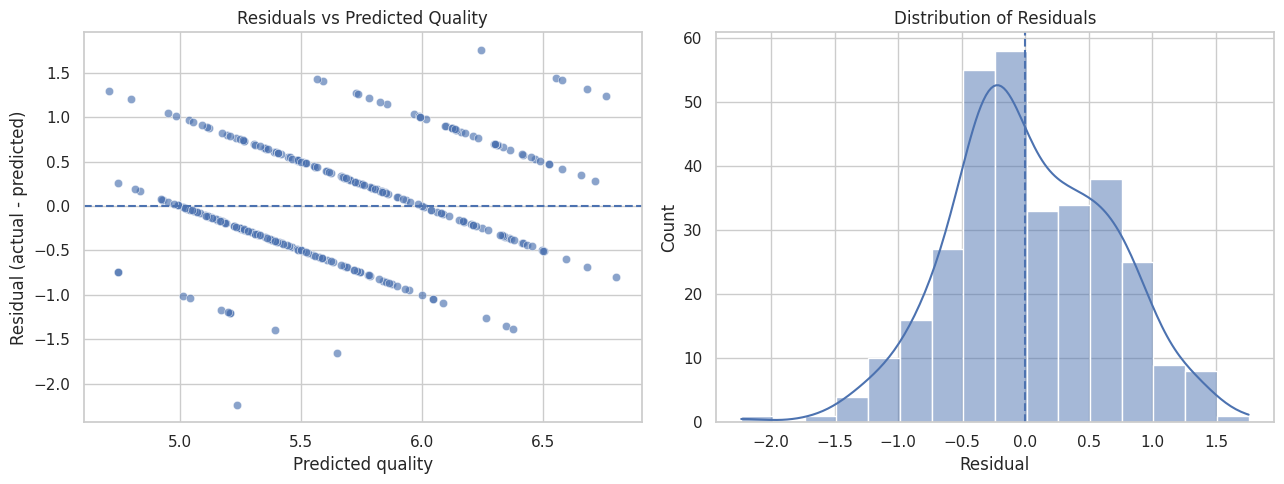

Mean residual: 0.033
Median residual: -0.0401


In [30]:
#Residual analysis


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

residuals = y_test_red - y_pred_linear

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residuals versus predicted quality
sns.scatterplot(
    x=y_pred_linear,
    y=residuals,
    alpha=0.65,
    ax=axes[0]
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuals vs Predicted Quality")
axes[0].set_xlabel("Predicted quality")
axes[0].set_ylabel("Residual (actual - predicted)")

# Distribution of residuals
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 4))
print("Median residual:", round(residuals.median(), 4))


In [31]:
#Checking prediction errors by actual quality
import pandas as pd
import numpy as np

error_analysis = pd.DataFrame({
    "actual_quality": y_test_red.to_numpy(),
    "predicted_quality": y_pred_linear
})

error_analysis["absolute_error"] = (
    error_analysis["actual_quality"]
    - error_analysis["predicted_quality"]
).abs()

error_analysis["residual"] = (
    error_analysis["actual_quality"]
    - error_analysis["predicted_quality"]
)

quality_errors = (
    error_analysis
    .groupby("actual_quality")
    .agg(
        sample_count=("actual_quality", "size"),
        mean_absolute_error=("absolute_error", "mean"),
        mean_residual=("residual", "mean")
    )
    .round(3)
)

display(quality_errors)


,sample_count,mean_absolute_error,mean_residual
actual_quality,,,
3,1,2.234,-2.234
4,10,1.136,-1.136
5,130,0.397,-0.383
6,132,0.410,0.243
7,42,0.824,0.824
8,5,1.435,1.435


In [32]:

baseline_summary = pd.DataFrame([
    {
        "Model": "Dummy Regressor",
        "MAE": dummy_results["MAE"],
        "RMSE": dummy_results["RMSE"],
        "R2": dummy_results["R²"]
    },
    {
        "Model": "Linear Regression",
        "MAE": linear_results["MAE"],
        "RMSE": linear_results["RMSE"],
        "R2": linear_results["R²"]
    },
    {
        "Model": "Ridge alpha=1",
        "MAE": ridge_results["MAE"],
        "RMSE": ridge_results["RMSE"],
        "R2": ridge_results["R²"]
    },
    {
        "Model": "Tuned Ridge alpha=10",
        "MAE": tuned_ridge_results["MAE"],
        "RMSE": tuned_ridge_results["RMSE"],
        "R2": tuned_ridge_results["R²"]
    }
])

display(baseline_summary.round(4))

baseline_summary.to_csv(
    "winelens_red_baseline_results.csv",
    index=False
)

print("Saved: winelens_red_baseline_results.csv")


,Model,MAE,RMSE,R2
0,Dummy Regressor,0.6853,0.8107,-0.0056
1,Linear Regression,0.5035,0.6245,0.4032
2,Ridge alpha=1,0.5036,0.6245,0.4032
3,Tuned Ridge alpha=10,0.5038,0.6246,0.4029


Saved: winelens_red_baseline_results.csv


**MOdel comparision**

In [33]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Training Random Forest on the same red-wine training split
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_red, y_train_red)

# Predicted on the held-out test set
y_pred_rf = rf_model.predict(X_test_red)

rf_results = {
    "Model": "Random Forest",
    "MAE": mean_absolute_error(y_test_red, y_pred_rf),
    "RMSE": np.sqrt(mean_squared_error(y_test_red, y_pred_rf)),
    "R²": r2_score(y_test_red, y_pred_rf)
}

comparison_week5 = pd.DataFrame([
    dummy_results,
    linear_results,
    rf_results
])

display(comparison_week5.round(4))


,Model,MAE,RMSE,R²
0,Dummy Regressor (mean),0.6853,0.8107,-0.0056
1,Linear Regression,0.5035,0.6245,0.4032
2,Random Forest,0.4238,0.5536,0.5311


In [34]:
#Gradient Boosting

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_red, y_train_red)

y_pred_gb = gb_model.predict(X_test_red)

gb_results = {
    "Model": "Gradient Boosting",
    "MAE": mean_absolute_error(y_test_red, y_pred_gb),
    "RMSE": np.sqrt(mean_squared_error(y_test_red, y_pred_gb)),
    "R²": r2_score(y_test_red, y_pred_gb)
}

comparison_week5 = pd.DataFrame([
    dummy_results,
    linear_results,
    rf_results,
    gb_results
])

display(comparison_week5.round(4))


,Model,MAE,RMSE,R²
0,Dummy Regressor (mean),0.6853,0.8107,-0.0056
1,Linear Regression,0.5035,0.6245,0.4032
2,Random Forest,0.4238,0.5536,0.5311
3,Gradient Boosting,0.4849,0.6019,0.4456


In [35]:
#Tuning Random Forests


from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error
import pandas as pd

rf_param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt"]
}

rf_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_grid=rf_param_grid,
    scoring="neg_mean_absolute_error",
    cv=rf_cv,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_red, y_train_red)

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest mean CV MAE:")
print(round(-rf_search.best_score_, 4))

rf_cv_results = pd.DataFrame(rf_search.cv_results_)

display(
    rf_cv_results[
        [
            "param_n_estimators",
            "param_max_depth",
            "param_min_samples_leaf",
            "param_max_features",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .assign(
        mean_CV_MAE=lambda x: -x["mean_test_score"]
    )
    .sort_values("mean_CV_MAE")
    .head(10)
    .round(4)
)


Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}

Best mean CV MAE:
0.431


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score,mean_CV_MAE
6,200,None,1,sqrt,-0.4310,0.0209,0.4310
1,400,None,1,1.0,-0.4314,0.0215,0.4314
30,200,20,1,sqrt,-0.4314,0.0206,0.4314
25,400,20,1,1.0,-0.4314,0.0213,0.4314
24,200,20,1,1.0,-0.4315,0.0210,0.4315
0,200,None,1,1.0,-0.4316,0.0211,0.4316
7,400,None,1,sqrt,-0.4322,0.0201,0.4322
31,400,20,1,sqrt,-0.4324,0.0201,0.4324
26,200,20,2,1.0,-0.4378,0.0213,0.4378
2,200,None,2,1.0,-0.4378,0.0213,0.4378


In [36]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# GridSearchCV has refitted the best model on all training data
best_rf = rf_search.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test_red)

tuned_rf_results = {
    "Model": "Tuned Random Forest",
    "MAE": mean_absolute_error(y_test_red, y_pred_rf_tuned),
    "RMSE": np.sqrt(mean_squared_error(y_test_red, y_pred_rf_tuned)),
    "R²": r2_score(y_test_red, y_pred_rf_tuned)
}

week5_comparison = pd.DataFrame([
    dummy_results,
    linear_results,
    rf_results,
    gb_results,
    tuned_rf_results
])

display(week5_comparison.round(4))


,Model,MAE,RMSE,R²
0,Dummy Regressor (mean),0.6853,0.8107,-0.0056
1,Linear Regression,0.5035,0.6245,0.4032
2,Random Forest,0.4238,0.5536,0.5311
3,Gradient Boosting,0.4849,0.6019,0.4456
4,Tuned Random Forest,0.4140,0.5406,0.5528


In [37]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predictions on training and test data
y_train_pred_rf = best_rf.predict(X_train_red)
y_test_pred_rf = best_rf.predict(X_test_red)

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }

overfit_check = pd.DataFrame({
    "Training": regression_metrics(y_train_red, y_train_pred_rf),
    "Test": regression_metrics(y_test_red, y_test_pred_rf)
}).T

display(overfit_check.round(4))


,MAE,RMSE,R²
Training,0.1536,0.2163,0.9281
Test,0.4140,0.5406,0.5528


In [38]:
#Testing more randomforest


from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold
import pandas as pd

rf_regularized_grid = {
    "n_estimators": [200],
    "max_depth": [8, 12, 16],
    "min_samples_leaf": [2, 4, 6],
    "max_features": ["sqrt", 1.0]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

rf_regularized_search = GridSearchCV(
    RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_grid=rf_regularized_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

rf_regularized_search.fit(X_train_red, y_train_red)

print("Best parameters:")
print(rf_regularized_search.best_params_)

print(
    "Best mean CV MAE:",
    round(-rf_regularized_search.best_score_, 4)
)

regularized_results = pd.DataFrame(
    rf_regularized_search.cv_results_
)

display(
    regularized_results[
        [
            "param_max_depth",
            "param_min_samples_leaf",
            "param_max_features",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .assign(
        mean_CV_MAE=lambda x: -x["mean_test_score"]
    )
    .sort_values("mean_CV_MAE")
    .head(10)
    .round(4)
)


Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:
{'max_depth': 16, 'max_features': 1.0, 'min_samples_leaf': 2, 'n_estimators': 200}
Best mean CV MAE: 0.4382


,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score,mean_CV_MAE
15,16,2,1.0,-0.4382,0.0216,0.4382
9,12,2,1.0,-0.4419,0.0213,0.4419
12,16,2,sqrt,-0.4459,0.0207,0.4459
6,12,2,sqrt,-0.4500,0.0174,0.4500
16,16,4,1.0,-0.4512,0.0194,0.4512
10,12,4,1.0,-0.4525,0.0194,0.4525
3,8,2,1.0,-0.4584,0.0199,0.4584
13,16,4,sqrt,-0.4591,0.0179,0.4591
17,16,6,1.0,-0.4607,0.0187,0.4607
11,12,6,1.0,-0.4608,0.0188,0.4608


In [39]:
#Evaluating the regularized forest on the test set


from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

best_rf_regularized = rf_regularized_search.best_estimator_

y_pred_rf_regularized = best_rf_regularized.predict(X_test_red)

regularized_test_results = {
    "Model": "Regularized Random Forest",
    "MAE": mean_absolute_error(y_test_red, y_pred_rf_regularized),
    "RMSE": np.sqrt(
        mean_squared_error(y_test_red, y_pred_rf_regularized)
    ),
    "R²": r2_score(y_test_red, y_pred_rf_regularized)
}

final_rf_comparison = pd.DataFrame([
    rf_results,
    tuned_rf_results,
    regularized_test_results
])

display(final_rf_comparison.round(4))

# Compare training and test performance for the regularized model
y_train_pred_regularized = best_rf_regularized.predict(X_train_red)

overfit_comparison = pd.DataFrame({
    "Training": {
        "MAE": mean_absolute_error(y_train_red, y_train_pred_regularized),
        "RMSE": np.sqrt(
            mean_squared_error(y_train_red, y_train_pred_regularized)
        ),
        "R²": r2_score(y_train_red, y_train_pred_regularized)
    },
    "Test": {
        "MAE": mean_absolute_error(y_test_red, y_pred_rf_regularized),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_red, y_pred_rf_regularized)
        ),
        "R²": r2_score(y_test_red, y_pred_rf_regularized)
    }
}).T

print("\nTraining vs test performance:")
display(overfit_comparison.round(4))


,Model,MAE,RMSE,R²
0,Random Forest,0.4238,0.5536,0.5311
1,Tuned Random Forest,0.4140,0.5406,0.5528
2,Regularized Random Forest,0.4324,0.5596,0.5207



Training vs test performance:


,MAE,RMSE,R²
Training,0.1984,0.2843,0.8757
Test,0.4324,0.5596,0.5207


,Feature,Importance
0,alcohol,0.1968
1,sulphates,0.1456
2,volatile acidity,0.1148
3,total sulfur dioxide,0.0835
4,density,0.0835
5,chlorides,0.0723
6,citric acid,0.0707
7,pH,0.0606
8,fixed acidity,0.0604
9,residual sugar,0.0588


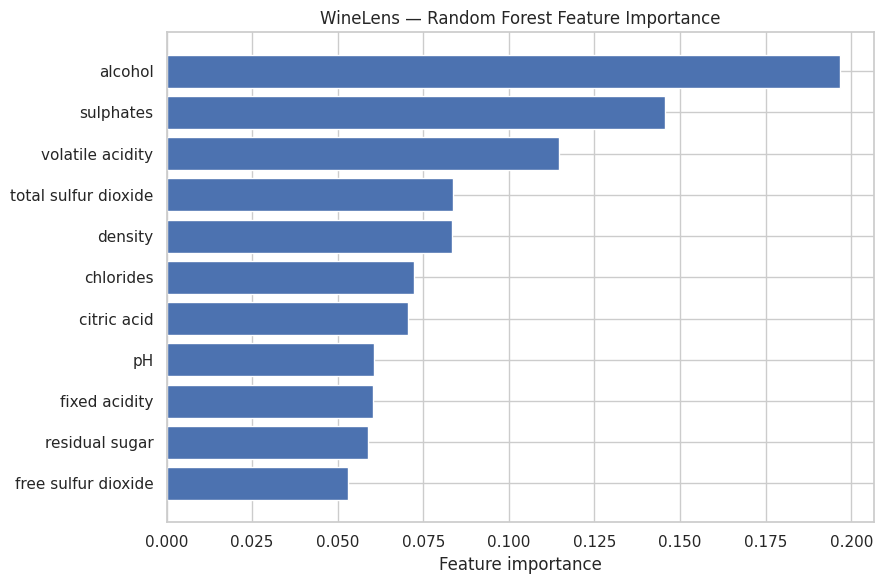

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Use the current best model: tuned Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train_red.columns,
    "Importance": rf_search.best_estimator_.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

plt.figure(figsize=(9, 6))
plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)
plt.xlabel("Feature importance")
plt.title("WineLens — Random Forest Feature Importance")
plt.tight_layout()
plt.show()

,Feature,Importance (MAE increase),Std
0,alcohol,0.1243,0.0110
1,sulphates,0.1018,0.0078
2,volatile acidity,0.0631,0.0069
3,total sulfur dioxide,0.0389,0.0040
4,density,0.0355,0.0032
5,citric acid,0.0276,0.0033
6,pH,0.0193,0.0030
7,fixed acidity,0.0192,0.0019
8,chlorides,0.0188,0.0032
9,free sulfur dioxide,0.0179,0.0032


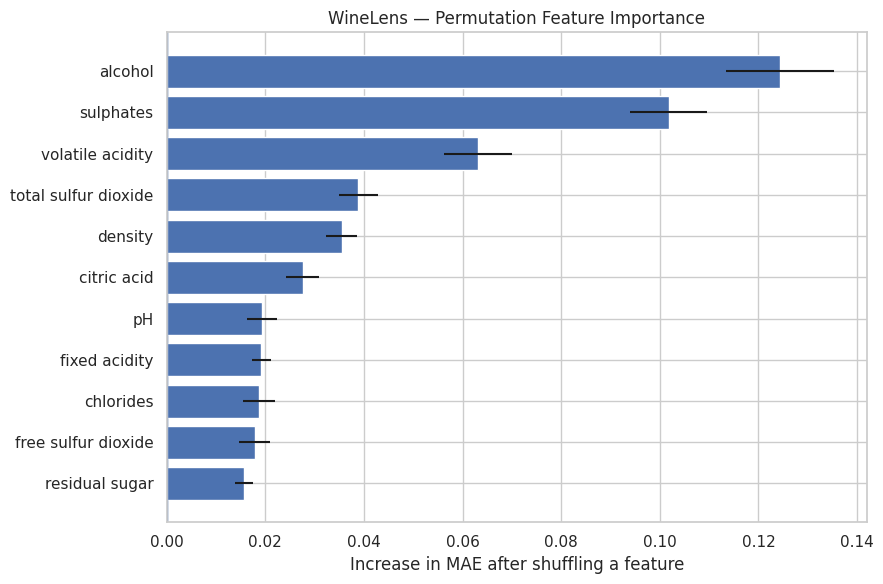

In [41]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate how much each feature matters to test-set predictions
perm_result = permutation_importance(
    rf_search.best_estimator_,
    X_test_red,
    y_test_red,
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test_red.columns,
    "Importance (MAE increase)": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values(
    "Importance (MAE increase)", ascending=False
).reset_index(drop=True)

display(permutation_df.round(4))

plt.figure(figsize=(9, 6))
plt.barh(
    permutation_df["Feature"][::-1],
    permutation_df["Importance (MAE increase)"][::-1],
    xerr=permutation_df["Std"][::-1]
)
plt.axvline(0, linewidth=1)
plt.xlabel("Increase in MAE after shuffling a feature")
plt.title("WineLens — Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [42]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

# Log-transform only the positively skewed features selected for this experiment.
log_features = ["residual sugar", "chlorides", "sulphates"]

X_train_log = X_train_red.copy()
X_test_log = X_test_red.copy()

for feature in log_features:
    X_train_log[feature] = np.log1p(X_train_log[feature])
    X_test_log[feature] = np.log1p(X_test_log[feature])

# Keep the best model's parameters; fit a fresh estimator on transformed data.
best_params = rf_search.best_params_

log_rf = RandomForestRegressor(
    **best_params,
    random_state=42,
    n_jobs=-1
)

log_rf.fit(X_train_log, y_train_red)
pred_log_rf = log_rf.predict(X_test_log)

# Evaluate the original tuned model on the same test rows.
pred_original_rf = rf_search.best_estimator_.predict(X_test_red)

comparison = pd.DataFrame([
    {
        "Model": "Tuned RF — original features",
        "MAE": mean_absolute_error(y_test_red, pred_original_rf),
        "RMSE": np.sqrt(mean_squared_error(y_test_red, pred_original_rf)),
        "R²": r2_score(y_test_red, pred_original_rf)
    },
    {
        "Model": "Tuned RF — log-transformed features",
        "MAE": mean_absolute_error(y_test_red, pred_log_rf),
        "RMSE": np.sqrt(mean_squared_error(y_test_red, pred_log_rf)),
        "R²": r2_score(y_test_red, pred_log_rf)
    }
])

display(comparison.round(4))

,Model,MAE,RMSE,R²
0,Tuned RF — original features,0.4140,0.5406,0.5528
1,Tuned RF — log-transformed features,0.4142,0.5408,0.5525


In [43]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, mean_absolute_error

# Use the current best model and the untouched test set.
best_model = rf_search.best_estimator_
predictions = best_model.predict(X_test_red)

# Wine quality scores are integers, but regression predictions can be decimals.
rounded_predictions = np.clip(
    np.rint(predictions), 0, 10
).astype(int)

actual = np.asarray(y_test_red).astype(int)
absolute_errors = np.abs(actual - rounded_predictions)

error_summary = pd.DataFrame({
    "Error category": [
        "Exact prediction",
        "Off by 1 point",
        "Off by 2 points",
        "Off by 3+ points"
    ],
    "Count": [
        np.sum(absolute_errors == 0),
        np.sum(absolute_errors == 1),
        np.sum(absolute_errors == 2),
        np.sum(absolute_errors >= 3)
    ]
})

error_summary["Percentage"] = (
    error_summary["Count"] / len(actual) * 100
)

display(error_summary.round(2))

print(
    "MAE after rounding predictions:",
    round(mean_absolute_error(actual, rounded_predictions), 4)
)

print(
    "Percentage within 1 quality point:",
    round(np.mean(absolute_errors <= 1) * 100, 2),
    "%"
)


,Error category,Count,Percentage
0,Exact prediction,210,65.62
1,Off by 1 point,108,33.75
2,Off by 2 points,2,0.62
3,Off by 3+ points,0,0.00


MAE after rounding predictions: 0.35
Percentage within 1 quality point: 99.38 %


In [44]:

import pandas as pd
import numpy as np

# Reuse actual test scores and rounded predictions from the previous cell.
prediction_results = pd.DataFrame({
    "Actual quality": actual,
    "Predicted quality": rounded_predictions
})

prediction_results["Error"] = (
    prediction_results["Predicted quality"]
    - prediction_results["Actual quality"]
)

# Summarize prediction behavior for each actual quality level.
quality_error_summary = (
    prediction_results
    .groupby("Actual quality")
    .agg(
        Number_of_wines=("Predicted quality", "size"),
        Mean_predicted_quality=("Predicted quality", "mean"),
        Exact_matches=("Error", lambda x: (x == 0).sum()),
        Mean_absolute_error=("Error", lambda x: np.abs(x).mean()),
        Mean_signed_error=("Error", "mean")
    )
    .reset_index()
)

display(quality_error_summary.round(3))

# Inspect the most frequent actual-versus-predicted combinations.
display(
    pd.crosstab(
        prediction_results["Actual quality"],
        prediction_results["Predicted quality"],
        rownames=["Actual"],
        colnames=["Predicted"]
    )
)


,Actual quality,Number_of_wines,Mean_predicted_quality,Exact_matches,Mean_absolute_error,Mean_signed_error
0,3,1,5.000,0,2.000,2.000
1,4,10,5.100,0,1.100,1.100
2,5,130,5.238,99,0.238,0.238
3,6,132,5.795,95,0.280,-0.205
4,7,42,6.381,16,0.619,-0.619
5,8,5,7.000,0,1.000,-1.000


Predicted,5,6,7
Actual,,,
3,1,0,0
4,9,1,0
5,99,31,0
6,32,95,5
7,0,26,16
8,0,0,5


In [45]:

import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

quality_classifier = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

quality_classifier.fit(X_train_red, y_train_red)
predicted_classes = quality_classifier.predict(X_test_red)

classification_metrics = pd.DataFrame([{
    "Model": "Balanced Random Forest Classifier",
    "Accuracy": accuracy_score(y_test_red, predicted_classes),
    "Balanced accuracy": balanced_accuracy_score(
        y_test_red, predicted_classes
    ),
    "Macro F1": f1_score(
        y_test_red, predicted_classes, average="macro", zero_division=0
    )
}])

display(classification_metrics.round(4))

print(classification_report(
    y_test_red,
    predicted_classes,
    labels=sorted(y_test_red.unique()),
    zero_division=0
))


,Model,Accuracy,Balanced accuracy,Macro F1
0,Balanced Random Forest Classifier,0.6812,0.3368,0.3373


              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.73      0.78      0.76       130
           6       0.64      0.71      0.67       132
           7       0.69      0.52      0.59        42
           8       0.00      0.00      0.00         5

    accuracy                           0.68       320
   macro avg       0.34      0.34      0.34       320
weighted avg       0.65      0.68      0.66       320



In [46]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    mean_absolute_error
)

# Regression predictions, rounded to integer quality scores
reg_pred = np.clip(
    np.rint(rf_search.best_estimator_.predict(X_test_red)),
    0, 10
).astype(int)

# Direct classification predictions
clf_pred = quality_classifier.predict(X_test_red)

y_true = np.asarray(y_test_red).astype(int)

fair_comparison = pd.DataFrame([
    {
        "Model": "Tuned RF Regressor (rounded)",
        "Accuracy": accuracy_score(y_true, reg_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, reg_pred),
        "Macro F1": f1_score(y_true, reg_pred, average="macro", zero_division=0),
        "MAE": mean_absolute_error(y_true, reg_pred)
    },
    {
        "Model": "Balanced RF Classifier",
        "Accuracy": accuracy_score(y_true, clf_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, clf_pred),
        "Macro F1": f1_score(y_true, clf_pred, average="macro", zero_division=0),
        "MAE": mean_absolute_error(y_true, clf_pred)
    }
])

display(fair_comparison.round(4))

,Model,Accuracy,Balanced accuracy,Macro F1,MAE
0,Tuned RF Regressor (rounded),0.6562,0.3104,0.3113,0.3500
1,Balanced RF Classifier,0.6812,0.3368,0.3373,0.3406


In [47]:

import pandas as pd
import numpy as np

# Compare actual and predicted category counts on the same test set.
actual_counts = pd.Series(y_test_red).value_counts().sort_index()
predicted_counts = pd.Series(
    quality_classifier.predict(X_test_red)
).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Actual test count": actual_counts,
    "Predicted test count": predicted_counts
}).fillna(0).astype(int)

display(class_distribution)

print("\nPredicted class proportions:")
display(
    (class_distribution[["Predicted test count"]]
     / len(y_test_red) * 100).round(2)
)


,Actual test count,Predicted test count
3,1,0
4,10,1
5,130,140
6,132,147
7,42,32
8,5,0



Predicted class proportions:


,Predicted test count
3,0.00
4,0.31
5,43.75
6,45.94
7,10.00
8,0.00


In [48]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
import pandas as pd

weighted_subsample_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced_subsample",
    n_jobs=-1
)

weighted_subsample_rf.fit(X_train_red, y_train_red)
pred_subsample = weighted_subsample_rf.predict(X_test_red)

comparison = pd.DataFrame([
    {
        "Model": "Balanced RF (current)",
        "Accuracy": accuracy_score(
            y_test_red, quality_classifier.predict(X_test_red)
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_test_red, quality_classifier.predict(X_test_red)
        ),
        "Macro F1": f1_score(
            y_test_red, quality_classifier.predict(X_test_red),
            average="macro", zero_division=0
        )
    },
    {
        "Model": "Balanced-subample RF",
        "Accuracy": accuracy_score(y_test_red, pred_subsample),
        "Balanced accuracy": balanced_accuracy_score(
            y_test_red, pred_subsample
        ),
        "Macro F1": f1_score(
            y_test_red, pred_subsample,
            average="macro", zero_division=0
        )
    }
])

display(comparison.round(4))

print("Classification report — balanced_subsample:")
print(classification_report(
    y_test_red, pred_subsample,
    labels=sorted(y_test_red.unique()),
    zero_division=0
))


,Model,Accuracy,Balanced accuracy,Macro F1
0,Balanced RF (current),0.6812,0.3368,0.3373
1,Balanced-subample RF,0.6594,0.3224,0.3234


Classification report — balanced_subsample:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.70      0.76      0.73       130
           6       0.63      0.70      0.66       132
           7       0.65      0.48      0.55        42
           8       0.00      0.00      0.00         5

    accuracy                           0.66       320
   macro avg       0.33      0.32      0.32       320
weighted avg       0.63      0.66      0.64       320



## 5. Results and interpretation

In the original run, the tuned Random Forest regressor was the strongest regression model tested on the shared test split (MAE 0.4140, RMSE 0.5406, R² 0.5528). The balanced Random Forest classifier achieved 68.12% accuracy, 33.68% balanced accuracy, and macro F1 0.3373 on that same split.

These figures are exploratory because the test set was reused across multiple experiments. The classifier struggled with rare quality classes, while the regressor tended to predict toward common middle scores. Feature importance indicates predictive association within the fitted model, not causation.


### Historical comparison table

The next cell records previously observed metrics. It is a static summary, not a recomputation from fitted models. If an experiment changes, update this table from live metric dictionaries or regenerate it programmatically.

In [49]:

import pandas as pd

model_summary = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": 0.5035,
        "RMSE": 0.6245,
        "R2": 0.4032,
        "Notes": "Baseline regression model"
    },
    {
        "Model": "Default Random Forest Regressor",
        "MAE": 0.4238,
        "RMSE": 0.5536,
        "R2": 0.5311,
        "Notes": "Improved over linear regression"
    },
    {
        "Model": "Tuned Random Forest Regressor",
        "MAE": 0.4140,
        "RMSE": 0.5406,
        "R2": 0.5528,
        "Notes": "Best regression model tested"
    },
    {
        "Model": "Balanced Random Forest Classifier",
        "Accuracy": 0.6812,
        "Balanced accuracy": 0.3368,
        "Macro F1": 0.3373,
        "Notes": "Best classifier tested; rare classes remain difficult"
    },
    {
        "Model": "Balanced-subsample RF Classifier",
        "Accuracy": 0.6594,
        "Balanced accuracy": 0.3224,
        "Macro F1": 0.3234,
        "Notes": "Worse than balanced RF"
    }
])

model_summary.to_csv("winelens_model_comparison.csv", index=False)

display(model_summary.round(4))
print("Saved: winelens_model_comparison.csv")


,Model,MAE,RMSE,R2,Notes,Accuracy,Balanced accuracy,Macro F1
0,Linear Regression,0.5035,0.6245,0.4032,Baseline regression model,NaN,NaN,NaN
1,Default Random Forest Regressor,0.4238,0.5536,0.5311,Improved over linear regression,NaN,NaN,NaN
2,Tuned Random Forest Regressor,0.4140,0.5406,0.5528,Best regression model tested,NaN,NaN,NaN
3,Balanced Random Forest Classifier,NaN,NaN,NaN,Best classifier tested; rare classes remain di...,0.6812,0.3368,0.3373
4,Balanced-subsample RF Classifier,NaN,NaN,NaN,Worse than balanced RF,0.6594,0.3224,0.3234


Saved: winelens_model_comparison.csv


In [50]:
import joblib

# Save the fitted models
joblib.dump(
    quality_classifier,
    "winelens_classifier.joblib"
)

joblib.dump(
    rf_search.best_estimator_,
    "winelens_regressor.joblib"
)

print("Saved:")
print("- winelens_classifier.joblib")
print("- winelens_regressor.joblib")

Saved:
- winelens_classifier.joblib
- winelens_regressor.joblib


In [51]:
import joblib
import os

# Using absolute paths to prevent working directory issues
base_dir = "/content" if os.path.exists("/content") else "."
classifier_path = os.path.join(base_dir, "winelens_classifier.joblib")
regressor_path = os.path.join(base_dir, "winelens_regressor.joblib")

# Helpful diagnostic if files are missing
if not os.path.exists(classifier_path) or not os.path.exists(regressor_path):
    print("Current working directory:", os.getcwd())
    print("Files in directory:", os.listdir("."))
    raise AssertionError("One or both model files are missing! Please re-run the saving cell (VLHoLA6JONzF) first.")

classifier = joblib.load(classifier_path)
regressor = joblib.load(regressor_path)

print("CLASSIFIER")
print("Type:", type(classifier).__name__)
print("Features:", classifier.n_features_in_)
print("Quality classes:", classifier.classes_)

print("\nREGRESSOR")
print("Type:", type(regressor).__name__)
print("Features:", regressor.n_features_in_)

print("\nBoth model files loaded successfully.")

CLASSIFIER
Type: RandomForestClassifier
Features: 11
Quality classes: [3 4 5 6 7 8]

REGRESSOR
Type: RandomForestRegressor
Features: 11

Both model files loaded successfully.


In [52]:

import numpy as np
import pandas as pd

# Check feature compatibility
assert list(X_test_red.columns) == list(
    getattr(classifier, "feature_names_in_", X_test_red.columns)
), "Classifier feature order mismatch!"

assert list(X_test_red.columns) == list(
    getattr(regressor, "feature_names_in_", X_test_red.columns)
), "Regressor feature order mismatch!"

# Predictions from the saved models
saved_clf_pred = classifier.predict(X_test_red)
saved_reg_pred = regressor.predict(X_test_red)

# Compare with the in-memory model predictions
original_clf_pred = quality_classifier.predict(X_test_red)
original_reg_pred = rf_search.best_estimator_.predict(X_test_red)

print(
    "Classifier predictions identical:",
    np.array_equal(saved_clf_pred, original_clf_pred)
)

print(
    "Regressor predictions identical:",
    np.allclose(saved_reg_pred, original_reg_pred)
)

print("\nSample predictions:")
display(pd.DataFrame({
    "Actual quality": np.asarray(y_test_red)[:10],
    "Classifier prediction": saved_clf_pred[:10],
    "Regressor prediction": np.round(saved_reg_pred[:10], 2)
}))


Classifier predictions identical: True
Regressor predictions identical: True

Sample predictions:


,Actual quality,Classifier prediction,Regressor prediction
0,6,5,5.36
1,5,5,5.11
2,6,5,5.29
3,5,5,5.28
4,6,6,6.00
5,5,5,5.08
6,5,5,5.10
7,5,5,5.03
8,5,6,6.16
9,6,6,5.92


In [53]:

import os
import zipfile

model_files = [
    "winelens_classifier.joblib",
    "winelens_regressor.joblib"
]

# Verify both model files exist before packaging
for filename in model_files:
    assert os.path.exists(filename), f"Missing model file: {filename}"

zip_filename = "winelens_models.zip"

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in model_files:
        zipf.write(filename, arcname=filename)

print("Created:", zip_filename)
print("Files included:")
for filename in model_files:
    print(f"- {filename} ({os.path.getsize(filename) / 1024:.1f} KB)")


Created: winelens_models.zip
Files included:
- winelens_classifier.joblib (21137.5 KB)
- winelens_regressor.joblib (8349.1 KB)


## 6. Conclusions and limitations

### Findings from the experiments
- Alcohol, sulphates, and volatile acidity were among the strongest predictors in the Random Forest importance analyses.
- The tested log transformations did not meaningfully improve Random Forest performance.
- The tuned Random Forest regressor performed better than the tested linear baseline and default Random Forest on the shared test split.
- The classification experiment showed weak balanced performance across quality categories, especially rare classes.

### Limitations
- Target classes are imbalanced, and extreme quality scores have few examples.
- The data are observational; feature importance and correlation do not establish causation.
- The same test set was consulted repeatedly, so reported metrics are exploratory rather than a fully independent final evaluation.
- Predictions estimate recorded quality scores; they are not professional wine judgments.
- Results may not generalize to other producers, regions, vintages, or measurement processes.


